In [1]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from scipy.stats import mannwhitneyu
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

# ---- CHANGE THESE PATHS ----
DATA_PATH = r"C:\Users\minsa_\Downloads\Final_Features_MultiLabel.csv"
IMAGE_DIR = r"C:\Users\minsa_\OneDrive\Desktop\Disease_Cell_Images"
OUT_DIR   = r"C:\Users\minsa_\Desktop\Processed_SP_ML"     

OUT_W, OUT_H = 512, 384
RANDOM_STATE = 42
LABEL_COLS = ["FECD", "Guttata", "Folds", "PolyPleo", "LowCD"]
FEATURES = ["ECD_CD_cells_per_mm2", "ECD_Deficit", "SD", "CV", "HEX_percent", "Donor_Age"]
os.makedirs(os.path.join(OUT_DIR, "images"), exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Labelled rows:", len(df))

Labelled rows: 1048


In [2]:
# rebuilt exactly as in 02d (same rows, key and seed), so image and numbers-only models use IDENTICAL folds
train_all = df[df["Split"] == "train"].reset_index(drop=True)
strat_key = train_all["FECD"] * 4 + train_all["Guttata"] * 2 + train_all["Folds"]
fold_map = {}
for k, (_, va) in enumerate(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                            .split(train_all, strat_key, groups=train_all["Donor_Group"])):
    for tid in train_all.loc[va, "Tissue_ID"]:
        fold_map[tid] = k
df["CV_Fold"] = df["Tissue_ID"].map(fold_map).fillna(-1).astype(int)     # -1 = test row
pd.crosstab(df["CV_Fold"], df["Split"])

Split,test,train
CV_Fold,,
-1,210,0
0,0,168
1,0,168
2,0,167
3,0,168
4,0,167


In [3]:
def tissue_key(s):
    m = re.search(r"(\d{4,6})\s*([LR])", str(s))
    return (int(m.group(1)), m.group(2)) if m else None

files = [f for f in os.listdir(IMAGE_DIR) if f.lower().endswith("_sp.jpg")]
img_index = pd.DataFrame({"SP_File": files})
img_index["Key"] = img_index["SP_File"].map(tissue_key)
print("SP images in folder:", len(img_index), "| unparsed names:", img_index["Key"].isna().sum(),
      "| duplicate tissue+eye:", img_index["Key"].duplicated().sum())
img_index = img_index.dropna(subset=["Key"]).drop_duplicates("Key")

df["Key"] = df["Tissue_ID"].map(tissue_key)
m = df.merge(img_index, on="Key", how="left")
m["Has_Image"] = m["SP_File"].notna()
print("Rows with an image:", m["Has_Image"].sum(), "of", len(m))
display(pd.DataFrame({"With image": m.loc[m.Has_Image, LABEL_COLS + ["Normal"]].sum(),
                      "Without image": m.loc[~m.Has_Image, LABEL_COLS + ["Normal"]].sum()}))
print("Labelled rows with no image:")
m.loc[~m["Has_Image"], ["Tissue_ID", "Combination", "Split"]]

SP images in folder: 1042 | unparsed names: 0 | duplicate tissue+eye: 0
Rows with an image: 1033 of 1048


,With image,Without image
FECD,126,1
Guttata,100,0
Folds,380,0
PolyPleo,131,1
LowCD,125,1
Normal,490,14


Labelled rows with no image:


,Tissue_ID,Combination,Split
29,NEB-2020-09-12683 L,Normal,test
70,NEB-2020-10-12726 R,Normal,train
77,NEB-2020-10-12733 L,Normal,train
186,NEB-2022-10-14315 L,Normal,train
245,NEB-2023-02-14710 R,FECD + PolyPleo + LowCD,train
383,NEB-2023-04-14996 R,Normal,train
527,NEB-2023-08-15300 R,Normal,train
742,NEB-2024-06-16116 L,Normal,train
743,NEB-2024-06-16117 R,Normal,train
756,NEB-2024-06-16130 L,Normal,train


In [4]:
def read_gray(path):
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if g is None:
        raise ValueError(f"Cannot read {path}")
    return g

def quality_metrics(path):
    g = cv2.resize(read_gray(path), (640, 480), interpolation=cv2.INTER_AREA)
    return {"Q_Mean": g.mean(), "Q_Std": g.std(), "Q_Focus": cv2.Laplacian(g, cv2.CV_64F).var(),
            "Q_Dark": (g < 20).mean(), "Q_Saturated": (g > 245).mean()}

img = m[m["Has_Image"]].copy()
img = img.join(pd.DataFrame([quality_metrics(os.path.join(IMAGE_DIR, f)) for f in img["SP_File"]],
                            index=img.index))

FOCUS_LOW = img["Q_Focus"].quantile(0.02)      # blurriest 2%
DARK_HIGH = 0.45
def quality_flag(r):
    if r["Q_Std"] < 5 or r["Q_Saturated"] > 0.5:
        return "Unusable"                           # blank / white capture -> excluded
    if r["Q_Focus"] < FOCUS_LOW or r["Q_Dark"] > DARK_HIGH:
        return "Low"                                # kept, but flagged
    return "OK"

img["Quality"] = img.apply(quality_flag, axis=1)
print(f"Focus threshold: {FOCUS_LOW:.2f} | dark threshold: {DARK_HIGH}")
display(img["Quality"].value_counts())
img.loc[img["Quality"] == "Unusable", ["Tissue_ID", "Combination", "Q_Mean", "Q_Std"]]

Focus threshold: 23.11 | dark threshold: 0.45


Quality
OK          1011
Low           21
Unusable       1
Name: count, dtype: int64

,Tissue_ID,Combination,Q_Mean,Q_Std
955,NEB-2025-10-17551 L,Normal,255.0,0.0


In [5]:
rows = []
for lab in LABEL_COLS + ["Normal"]:
    r = {"Label": lab}
    for q in ["Q_Mean", "Q_Focus", "Q_Dark"]:
        a = img.loc[img[lab] == 1, q]; b = img.loc[img[lab] == 0, q]
        r[f"{q} (with / without)"] = f"{a.median():.2f} / {b.median():.2f}"
        r[f"{q} p"] = round(mannwhitneyu(a, b).pvalue, 4)
    r["Low-quality %"] = round((img.loc[img[lab] == 1, "Quality"] != "OK").mean() * 100, 1)
    rows.append(r)
print("Image quality: corneas WITH vs WITHOUT each disease (median)")
pd.DataFrame(rows)

Image quality: corneas WITH vs WITHOUT each disease (median)


,Label,Q_Mean (with / without),Q_Mean p,Q_Focus (with / without),Q_Focus p,Q_Dark (with / without),Q_Dark p,Low-quality %
0,FECD,82.26 / 79.86,0.2657,31.42 / 32.52,0.0145,0.07 / 0.09,0.0447,2.4
1,Guttata,80.53 / 80.14,0.5937,32.89 / 32.41,0.9386,0.10 / 0.08,0.0102,1.0
2,Folds,76.60 / 81.78,0.0000,31.24 / 33.25,0.0000,0.08 / 0.09,0.2906,4.2
3,PolyPleo,82.33 / 79.85,0.2512,31.39 / 32.54,0.0086,0.07 / 0.09,0.0484,2.3
4,LowCD,82.18 / 79.90,0.3165,31.46 / 32.50,0.0163,0.07 / 0.09,0.0398,2.4
5,Normal,81.49 / 79.38,0.0048,33.49 / 31.70,0.0000,0.09 / 0.08,0.9518,1.0


In [6]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def preprocess(path):
    g = cv2.resize(read_gray(path), (OUT_W, OUT_H), interpolation=cv2.INTER_AREA)
    return CLAHE.apply(g)

usable = img[img["Quality"] != "Unusable"].copy()
usable["Proc_File"] = usable["Tissue_ID"].str.replace(r"[^\w\-]+", "_", regex=True) + ".png"
for i, (_, r) in enumerate(usable.iterrows(), 1):
    out = os.path.join(OUT_DIR, "images", r["Proc_File"])
    if not os.path.exists(out):
        cv2.imwrite(out, preprocess(os.path.join(IMAGE_DIR, r["SP_File"])))
    if i % 200 == 0:
        print(f"{i}/{len(usable)}")
print("Processed images saved:", len(usable))

200/1032
400/1032
600/1032
800/1032
1000/1032
Processed images saved: 1032


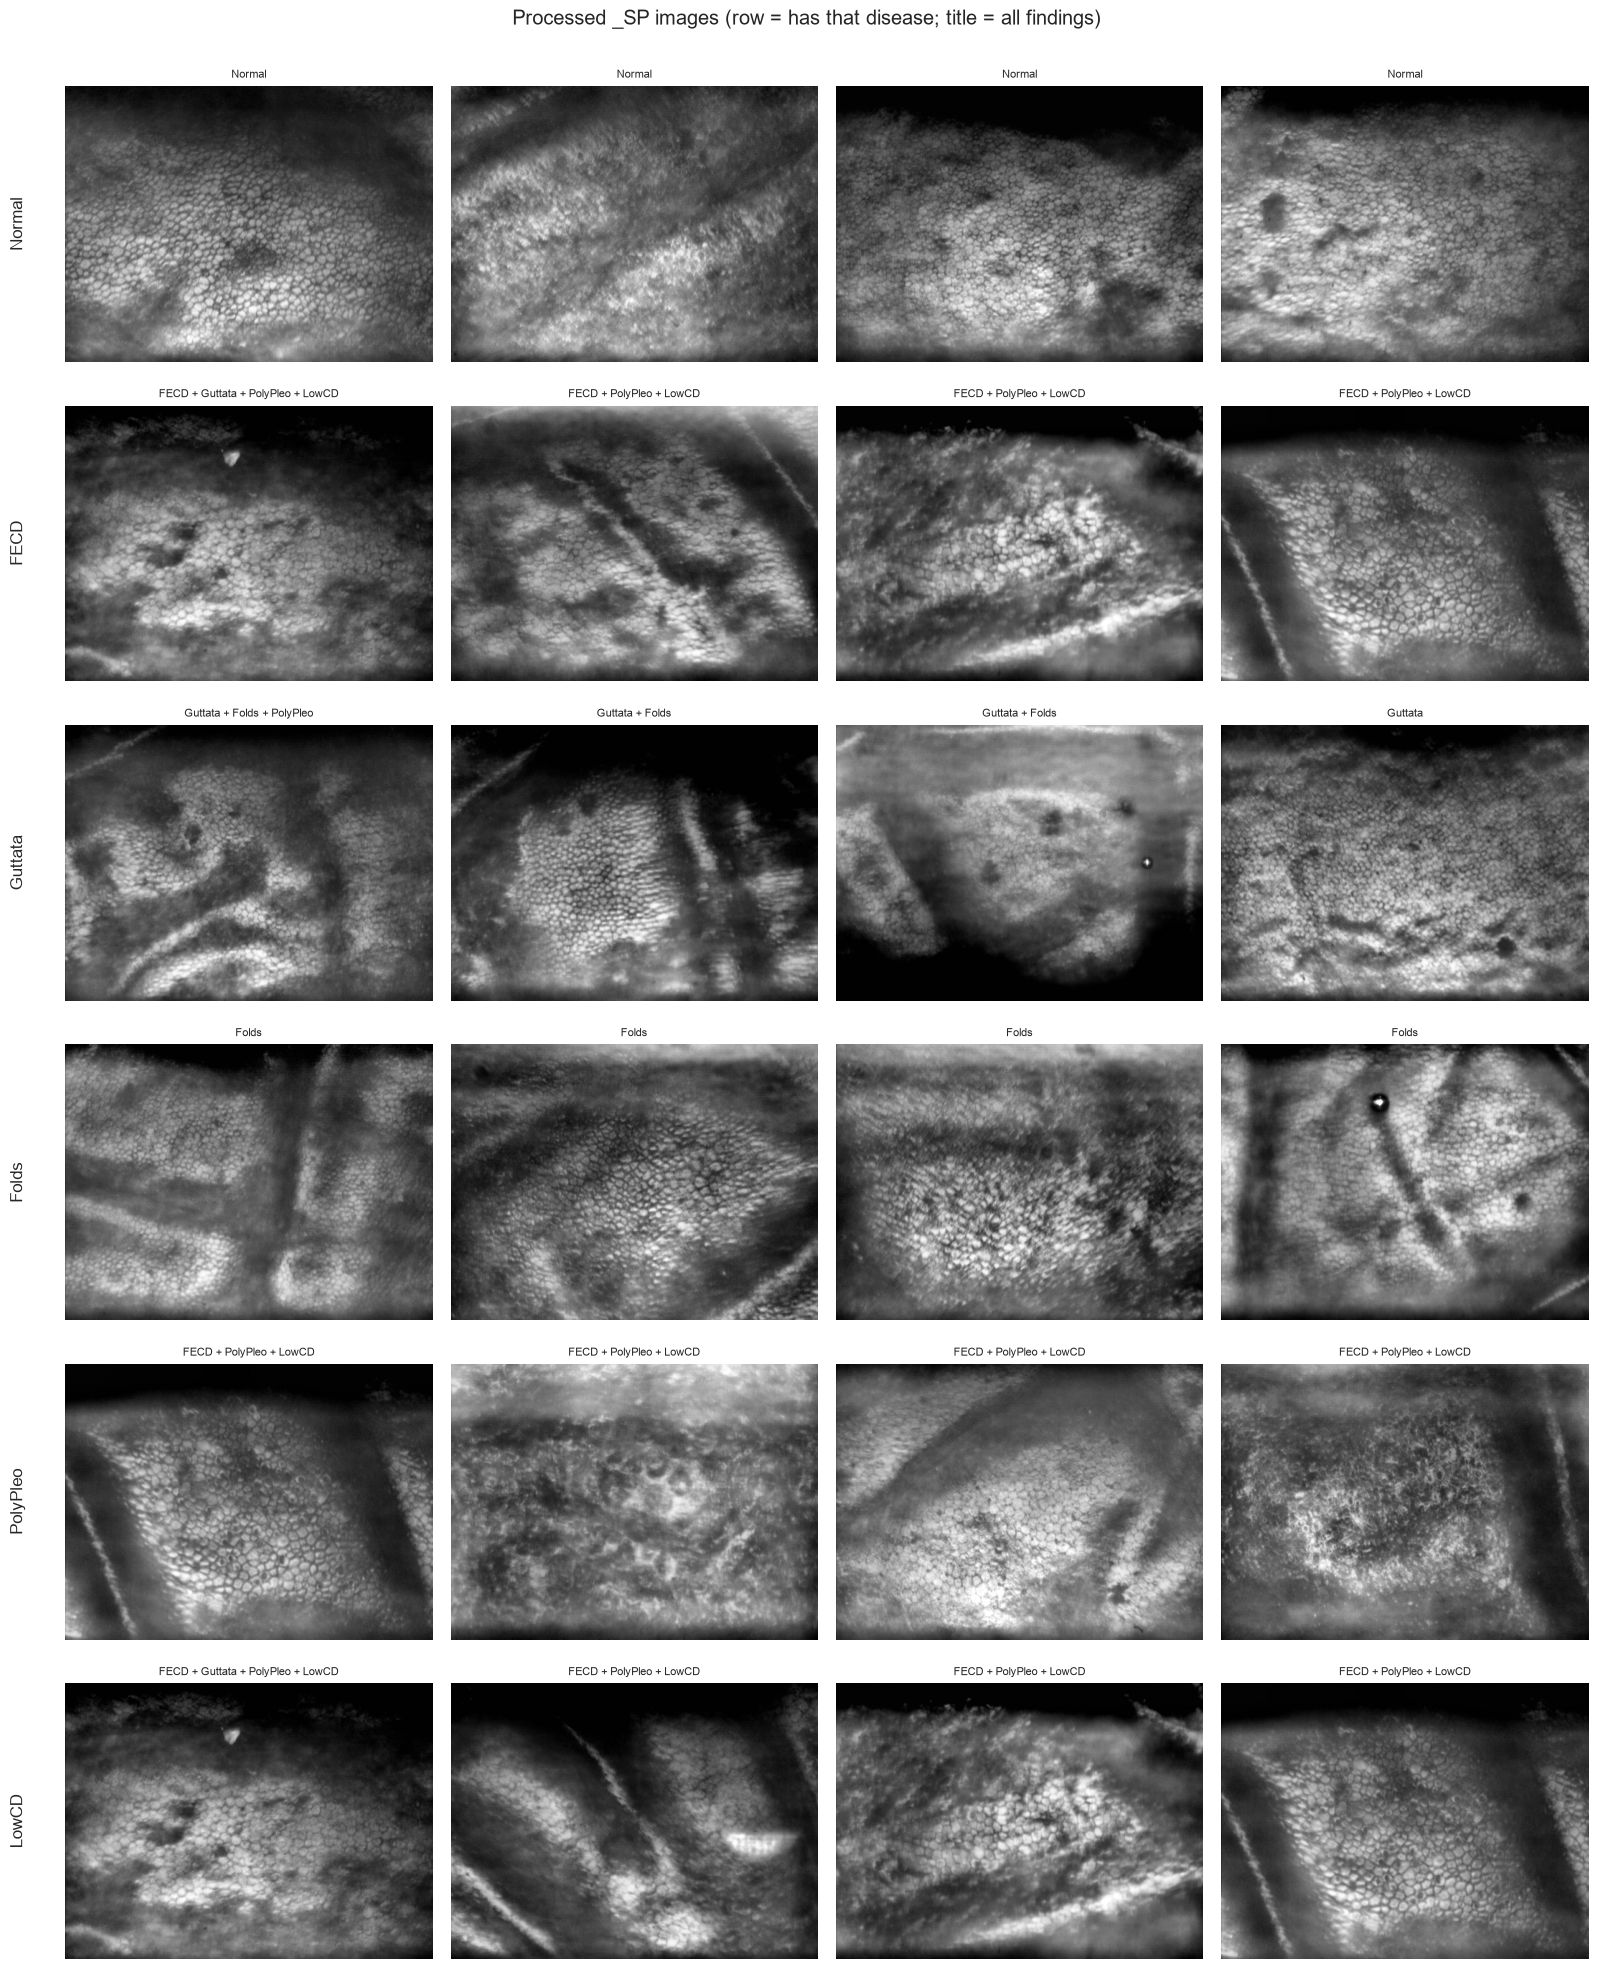

In [7]:
fig, axes = plt.subplots(len(LABEL_COLS) + 1, 4, figsize=(16, 3.3 * (len(LABEL_COLS) + 1)))
for i, lab in enumerate(["Normal"] + LABEL_COLS):
    sub = usable[(usable[lab] == 1) & (usable["Quality"] == "OK")].sample(4, random_state=3)
    for j, (_, r) in enumerate(sub.iterrows()):
        axes[i, j].imshow(cv2.imread(os.path.join(OUT_DIR, "images", r["Proc_File"]), 0), cmap="gray")
        axes[i, j].set_title(r["Combination"], fontsize=8); axes[i, j].axis("off")
    axes[i, 0].text(-0.15, 0.5, lab, transform=axes[i, 0].transAxes, rotation=90, va="center", fontsize=12)
plt.suptitle("Processed _SP images (row = has that disease; title = all findings)", y=1.0)
plt.tight_layout(); plt.show()

In [8]:
tr = usable[usable["Split"] == "train"]
print("Max folds per donor (must be 1):", tr.groupby("Donor_Group")["CV_Fold"].nunique().max())
print("Donors in both train and test:",
      len(set(tr["Donor_Group"]) & set(usable.loc[usable.Split == "test", "Donor_Group"])))
display(tr.groupby("CV_Fold")[LABEL_COLS + ["Normal"]].sum())

px = np.concatenate([cv2.imread(os.path.join(OUT_DIR, "images", f), 0).ravel()[::50]
                     for f in tr["Proc_File"]]) / 255.0
NORM = {"mean": float(px.mean()), "std": float(px.std())}
print("Train pixel mean/std:", {k: round(v, 4) for k, v in NORM.items()})

Max folds per donor (must be 1): 1
Donors in both train and test: 0


,FECD,Guttata,Folds,PolyPleo,LowCD,Normal
CV_Fold,,,,,,
0,20,16,61,22,20,76
1,21,17,62,21,21,80
2,21,16,61,24,23,74
3,20,16,61,20,20,78
4,19,16,61,18,18,82


Train pixel mean/std: {'mean': 0.3639, 'std': 0.1815}


In [9]:
keep = (["Tissue_ID", "Donor_Group", "Split", "CV_Fold", "SP_File", "Proc_File", "Disease_Label", "Combination"]
        + LABEL_COLS + ["Normal", "n_Diseases", "Target_Severity", "Quality",
           "Q_Mean", "Q_Std", "Q_Focus", "Q_Dark", "Q_Saturated"] + FEATURES)
manifest = usable[keep].reset_index(drop=True)
manifest.to_csv(os.path.join(OUT_DIR, "Image_Manifest_MultiLabel.csv"), index=False)

json.dump({"size": [OUT_W, OUT_H], "clahe": {"clipLimit": 2.0, "tileGridSize": [8, 8]},
           "normalisation": NORM, "features": FEATURES, "labels": LABEL_COLS,
           "quality_rules": {"unusable": "Q_Std < 5 or Q_Saturated > 0.5",
                             "low": f"Q_Focus < {FOCUS_LOW:.2f} or Q_Dark > {DARK_HIGH}"}},
          open(os.path.join(OUT_DIR, "image_config.json"), "w"), indent=2)

print("Saved:", os.path.join(OUT_DIR, "Image_Manifest_MultiLabel.csv"), manifest.shape)
pd.DataFrame({"Train": manifest.loc[manifest.Split == "train", LABEL_COLS + ["Normal"]].sum(),
              "Test":  manifest.loc[manifest.Split == "test",  LABEL_COLS + ["Normal"]].sum()})

Saved: C:\Users\minsa_\Desktop\Processed_SP_ML\Image_Manifest_MultiLabel.csv (1032, 28)


,Train,Test
FECD,101,25
Guttata,81,19
Folds,306,74
PolyPleo,105,26
LowCD,102,23
Normal,390,99
